# Supplementary: six adoption curves

`figures/fx-cumulative-cdr-adoptrate` compares cumulative CDR by 2100 across **six global
adoption curves**
| | $L$ = 4.6 Gt CO2/yr | $L$ = 0.5 Gt CO2/yr |
|---|---|---|
| **GCAM native** | `exe_central1p5` (the raw GCAM schedule) | `gcam-native_L0.5Gt` (same shape, rescaled) |
| **$k$ = 0.24 yr-1** | `nearterm-gcam-first10yrs_k_gcam_L_gcam` | `nearterm-gcam-first10yrs_k_gcam_L0.5Gt` |
| **$k$ = 0.13 yr-1** | `nearterm-gcam-first10yrs_k_nemetMedian_L_gcam` | `nearterm-gcam-first10yrs_k_nemetMedian_L0.5Gt` |


## Logistic growth formulation

Every curve is the same four-parameter logistic applied to global annual CDR (Mt CO2/yr):

$$C(t) = \frac{C_0\,L}{C_0 + (L - C_0)\,e^{-k(t - t_0)}}$$

In each of the four synthetic curves, the first decade is a fixed exponential ramp with rapid growth.
Variations in $k$ therefore only apply after the first decade:

| symbol | meaning | application |
|---|---|---|
| $L$ | asymptotic deployment ceiling | **varied**: 4.63 Gt CO2/yr (GCAM's own asymptote) or 0.5 Gt CO2/yr |
| $k$ | long-run growth rate | **varied**: 0.24 yr-1 (fit to GCAM) or 0.13 yr-1 (Nemet et al. 2023 median) |
| $C_0$, $t_0$ | near-term anchor | **held fixed**: 146 Mt CO2/yr in 2036 |
| $C_{ref}$, $t_{ref}$, $k_{ramp}$ | the ramp that sets $C_0$ | **held fixed**: cdr.fyi 2026 ERW sales (0.81 Mt CO2), grown at 0.52 yr-1 |


In [2]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from scipy.optimize import curve_fit

In [5]:
# --- [ GCAM donor + synthetic-curve archive ] ---
RUN_FORMAT, DEG_RES = "one-cell-per-region", 1
BASE_SCHEDULE = "exe_central1p5"            # GCAM schedule + donor
APPRATE_REF   = "10.0-tHaYr-appRate-FIXED"  # gcam_gross_cdr_mtCO2 is apprate-invariant; any one works
S3_GCAM   = f"s3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/{RUN_FORMAT}"
S3_CURVES = f"{S3_GCAM}/synthetic-rateConstrained"
rock_fn   = f"annual_rockflx_densest-ag-region_{DEG_RES}deg.pkl"

# --- [ postprocessed SCEPTER runs, for the closing check that the runs used these curves ] ---
S3_RUNS = ("s3://carbonplan-carbon-removal/ew-workflows-data/scepter/postprocessed/gcam/"
           "gcam_opr_full2_cec1/exe_central1p5_001_multiSchedule")
CHECK_DEPLOYED = True

# --- [ the six curves, matching fig-cumulative-cdr-adoptrate.ipynb ] ---
MAIN_CASE = "nearterm-gcam-first10yrs"
K_CASES   = ["k_nemetMedian", "k_gcam"]
L_CASES   = ["L_gcam", "L0.5Gt"]
NATIVE_SCHEDULE = {"L_gcam": BASE_SCHEDULE, "L0.5Gt": "gcam-native_L0.5Gt"}

# --- [ the empirical inputs that set C0, t0 and the ramp ] ---
C0_SALES_2026, C0_DELIV_2026 = 807.885e3 * 1e-6, 30.7e3 * 1e-6   # [Mt CO2] cdr.fyi ERW, 6/2026
YR_BASE_CDRFYI, YR_RAMP_END  = 2026, 2036
K_GCAM_10YR, K_NEMET_MEDIAN  = 0.52, 0.13                        # [yr-1]
RCO2_GCAM = 0.3                                                  # tCO2 / t basalt

# --- [ colors: same as the main figure, so the two read together ] ---
GCAM_COLOR = "#1a1a1a"
K_COLOR    = {"k_nemetMedian": "#9a6fb0", "k_gcam": "#4b2270"}
RAMP_COLOR = "#c1440e"
SALES_COLOR, DELIV_COLOR = "#2f6fed", "#e0733a"
RAMP_SHADE = "#d9d9d9"
CASE_COLOR = {MAIN_CASE: "#2f6fed", "cdrfyi-sales": "#e0733a", "cdrfyi-deliveries": "#2ca02c"}

FS_LAB, FS_TICK, FS_TITLE, FS_LEG, FS_LETTER = 13, 11, 13, 9, 15
LW = 2.2

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "axes.edgecolor": "#1a1a1a", "axes.linewidth": 1.0,
    "text.color": "#1a1a1a", "axes.labelcolor": "#1a1a1a",
    "xtick.color": "#1a1a1a", "ytick.color": "#1a1a1a",
})

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
savehere = REPO / "figures/supp"
(savehere / "panels").mkdir(parents=True, exist_ok=True)

## Read the curves


In [6]:
def logistic4(t, C0, L, k, t0):
    """C(t) = C0*L / (C0 + (L-C0)*e^{-k(t-t0)})."""
    return C0 * L / (C0 + (L - C0) * np.exp(-k * (t - t0)))


def build_curve(years, C0, L, k, t0, ramp=None):
    """logistic4 from t0 on; the prescribed exponential ramp before it."""
    curve = logistic4(years, C0, L, k, t0)
    if ramp is None:
        return curve
    return np.where(years < t0, ramp["C_ref"] * np.exp(ramp["k"] * (years - ramp["t_ref"])), curve)


def schedule_name(k, L):
    return f"{MAIN_CASE}_{k}_{L}"


# GCAM donor (sum of 32 regions)
df_base = pd.read_pickle(os.path.join(S3_GCAM, BASE_SCHEDULE, APPRATE_REF, rock_fn))
years   = np.sort(df_base["time"].unique()).astype(float)
donor   = df_base.groupby("time")["gcam_gross_cdr_mtCO2"].sum().reindex(years).values
print(f"donor {BASE_SCHEDULE}: {df_base['region_nospaces'].nunique()} regions, "
      f"{years.min():.0f}-{years.max():.0f}, peak {donor.max():,.0f} Mt CO2/yr")

# the five synthetic/rescaled curves
manifest = pd.read_csv(f"{S3_CURVES}/manifest.csv", index_col="schedule_name")
read_curve = lambda name: (pd.read_csv(f"{S3_CURVES}/{name}.csv", index_col="year")
                           ["value_mtco2_per_yr"].reindex(years).values)

curves = {BASE_SCHEDULE: donor}
for L in L_CASES:
    for k in K_CASES:
        curves[schedule_name(k, L)] = read_curve(schedule_name(k, L))
    if NATIVE_SCHEDULE[L] != BASE_SCHEDULE:
        curves[NATIVE_SCHEDULE[L]] = read_curve(NATIVE_SCHEDULE[L])

# refit the donor -- reproduces L and k_gcam rather than trusting the manifest for them
T0_REF = 2026
popt, _ = curve_fit(
    lambda t, C0, L, k: logistic4(t, C0, L, k, T0_REF), years, donor,
    p0=[max(float(np.interp(T0_REF, years, donor)), 1e-6), donor.max() * 3, 0.2],
    bounds=([1e-9, donor.max(), 1e-4], [np.inf, np.inf, 2.0]), maxfev=20000,
)
C0_fit, L_fit, k_fit = popt
manifest.loc[BASE_SCHEDULE, ["C0", "t0", "k", "L"]] = [C0_fit, T0_REF, k_fit, L_fit]
print(f"donor logistic fit: C0={C0_fit:,.1f} Mt CO2/yr at {T0_REF}, L={L_fit:,.1f} Mt CO2/yr, "
      f"k={k_fit:.3f} yr^-1")

L_VAL   = {L: float(manifest.loc[schedule_name(K_CASES[0], L), "L"]) for L in L_CASES}
K_VAL   = {k: float(manifest.loc[schedule_name(k, L_CASES[0]), "k"]) for k in K_CASES}
L_LABEL = {L: f"{L_VAL[L] / 1e3:.1f} Gt CO$_2$ yr$^{{-1}}$" for L in L_CASES}
K_LABEL = {k: f"$k$ = {K_VAL[k]:.2f} yr$^{{-1}}$" for k in K_CASES}
K_NAME  = {"k_gcam": "GCAM long-run", "k_nemetMedian": "Nemet median"}

# plot order used throughout: (name, L case, color, linestyle, label)
CURVE_ORDER = [
    item for L in L_CASES for item in (
        [(schedule_name(k, L), L, K_COLOR[k], "-" if L == "L_gcam" else (0, (5, 2)),
          f"{K_LABEL[k]}, $L$ = {L_LABEL[L]}") for k in K_CASES]
        + [(NATIVE_SCHEDULE[L], L, GCAM_COLOR, "-" if L == "L_gcam" else (0, (5, 2)),
            f"GCAM native, $L$ = {L_LABEL[L]}")]
    )
]
print(f"{len(curves)} curves loaded")

donor exe_central1p5: 32 regions, 2020-2100, peak 4,631 Mt CO2/yr
donor logistic fit: C0=213.4 Mt CO2/yr at 2026, L=4,630.9 Mt CO2/yr, k=0.240 yr^-1
6 curves loaded


In [7]:
summary = pd.DataFrame([
    dict(schedule=name,
         C0=manifest.loc[name, "C0"], t0=manifest.loc[name, "t0"],
         k=manifest.loc[name, "k"], L=manifest.loc[name, "L"],
         doubling_yr=np.log(2) / manifest.loc[name, "k"],
         peak_MtCO2_yr=curves[name].max(),
         cum_GtCO2_2100=curves[name].sum() / 1e3,
         cum_Gtrock_2100=curves[name].sum() / 1e3 / RCO2_GCAM)
    for name, *_ in CURVE_ORDER
]).set_index("schedule")

summary.style.format({"C0": "{:,.1f}", "t0": "{:.0f}", "k": "{:.2f}", "L": "{:,.0f}",
                      "doubling_yr": "{:.1f}", "peak_MtCO2_yr": "{:,.0f}",
                      "cum_GtCO2_2100": "{:,.0f}", "cum_Gtrock_2100": "{:,.0f}"}
                     ).set_caption("Parameters and totals for the six adoption curves")

,C0,t0,k,L,doubling_yr,peak_MtCO2_yr,cum_GtCO2_2100,cum_Gtrock_2100
schedule,,,,,,,,
nearterm-gcam-first10yrs_k_nemetMedian_L_gcam,146.4,2036,0.13,"4,631",5.3,"4,597",176,587
nearterm-gcam-first10yrs_k_gcam_L_gcam,146.4,2036,0.24,"4,631",2.9,"4,631",232,774
exe_central1p5,213.4,2026,0.24,"4,631",2.9,"4,631",285,948
nearterm-gcam-first10yrs_k_nemetMedian_L0.5Gt,146.4,2036,0.13,500,5.3,500,28,93
nearterm-gcam-first10yrs_k_gcam_L0.5Gt,146.4,2036,0.24,500,2.9,500,30,100
gcam-native_L0.5Gt,23.0,2026,0.24,500,2.9,500,31,102


## Figure — six adoption curves

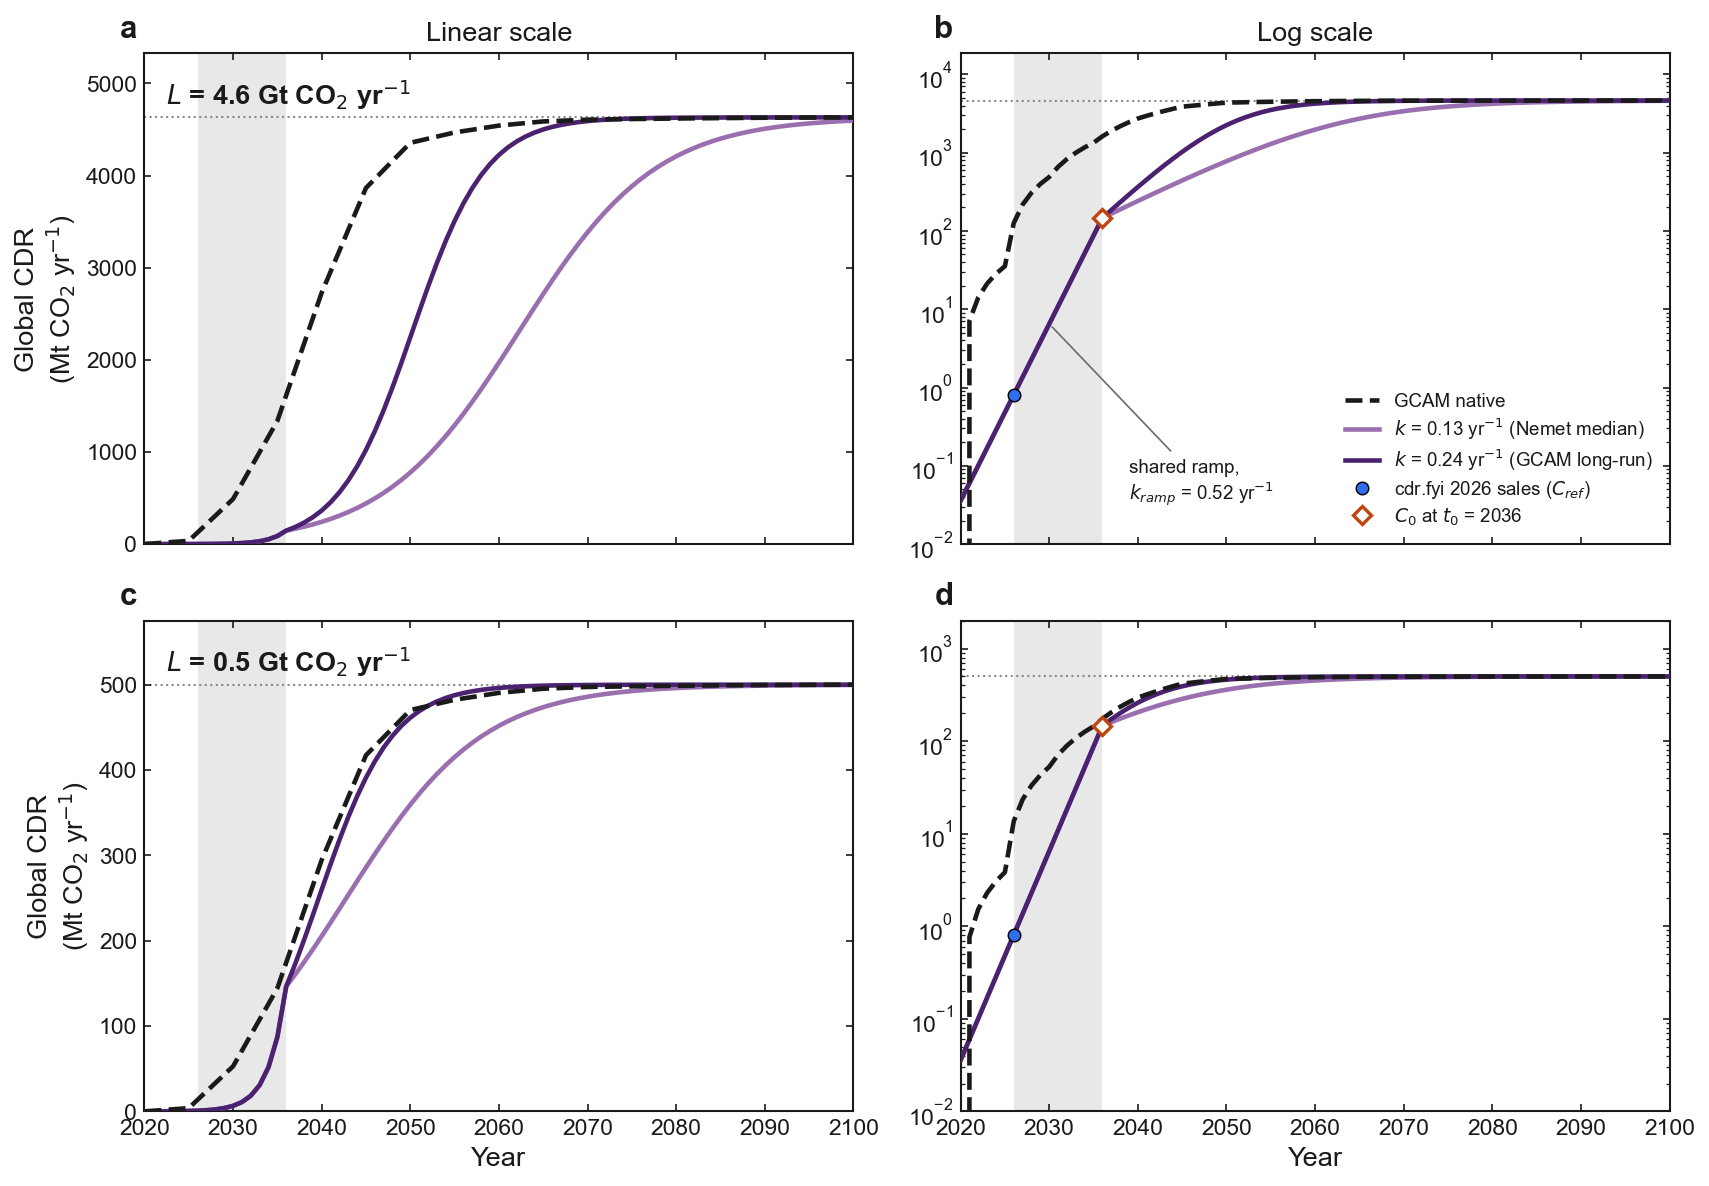

In [8]:
# ———————————————————————————————————
SAVE_ON  = True
# ———————————————————————————————————
fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.0), dpi=150, sharex=True)

for i, L in enumerate(L_CASES):
    for j, logy in enumerate([False, True]):
        ax = axes[i, j]
        ax.axvspan(YR_BASE_CDRFYI, YR_RAMP_END, color=RAMP_SHADE, alpha=0.6, lw=0, zorder=0)
        ax.axhline(L_VAL[L], color="#8a8a8a", ls=":", lw=1.0, zorder=1)

        ax.plot(years, curves[NATIVE_SCHEDULE[L]], color=GCAM_COLOR, ls="--", lw=LW, zorder=4,
                label="GCAM native" + ("" if L == "L_gcam" else " (rescaled)"))
        for k in K_CASES:
            ax.plot(years, curves[schedule_name(k, L)], color=K_COLOR[k], lw=LW, zorder=3,
                    label=f"{K_LABEL[k]} ({K_NAME[k]})")

        if logy:
            ax.set_yscale("log")
            ax.set_ylim(1e-2, L_VAL[L] * 4)
            ax.plot([YR_BASE_CDRFYI], [C0_SALES_2026], marker="o", ms=6, color=SALES_COLOR,
                    mec="k", mew=0.7, ls="none", zorder=5,
                    label="cdr.fyi 2026 sales ($C_{ref}$)")
            ax.plot([YR_RAMP_END], [manifest.loc[schedule_name(K_CASES[0], L), "C0"]], marker="D",
                    ms=6, color="w", mec=RAMP_COLOR, mew=1.6, ls="none", zorder=5,
                    label="$C_0$ at $t_0$ = 2036")
        else:
            ax.set_ylim(0, L_VAL[L] * 1.15)

        ax.set_xlim(years.min(), years.max())
        ax.tick_params(which="both", direction="in", top=True, right=True, labelsize=FS_TICK)
        if i == 0:
            ax.set_title(["Linear scale", "Log scale"][j], fontsize=FS_TITLE)
        if i == len(L_CASES) - 1:
            ax.set_xlabel("Year", fontsize=FS_LAB)
        if j == 0:
            ax.set_ylabel("Global CDR\n(Mt CO$_2$ yr$^{-1}$)", fontsize=FS_LAB)
            ax.text(0.03, 0.95, f"$L$ = {L_LABEL[L]}", transform=ax.transAxes, va="top",
                    fontsize=FS_LAB, fontweight="bold")

axes[0, 1].legend(fontsize=FS_LEG, frameon=False, loc="lower right", handlelength=1.8,
                  labelspacing=0.3)
axes[0, 1].annotate("shared ramp,\n$k_{ramp}$ = 0.52 yr$^{-1}$", xy=(2030, 6.5),
                    xytext=(2039, 0.06), fontsize=FS_LEG, ha="left", va="center",
                    arrowprops=dict(arrowstyle="-", lw=0.8, color="#6a6a6a"))
for letter, ax in zip("abcd", axes.ravel()):
    ax.text(-0.01, 1.02, letter, transform=ax.transAxes, ha="right", va="bottom",
            fontsize=FS_LETTER, fontweight="bold")

fig.tight_layout(h_pad=1.0, w_pad=1.4)
if SAVE_ON:
    fig.savefig(os.path.join(savehere, "panels", "adoption-curves-six.png"),
                dpi=300, bbox_inches="tight", transparent=False)
plt.show()
plt.close();

## Figure — near-term growth + cdr.fyi numbers


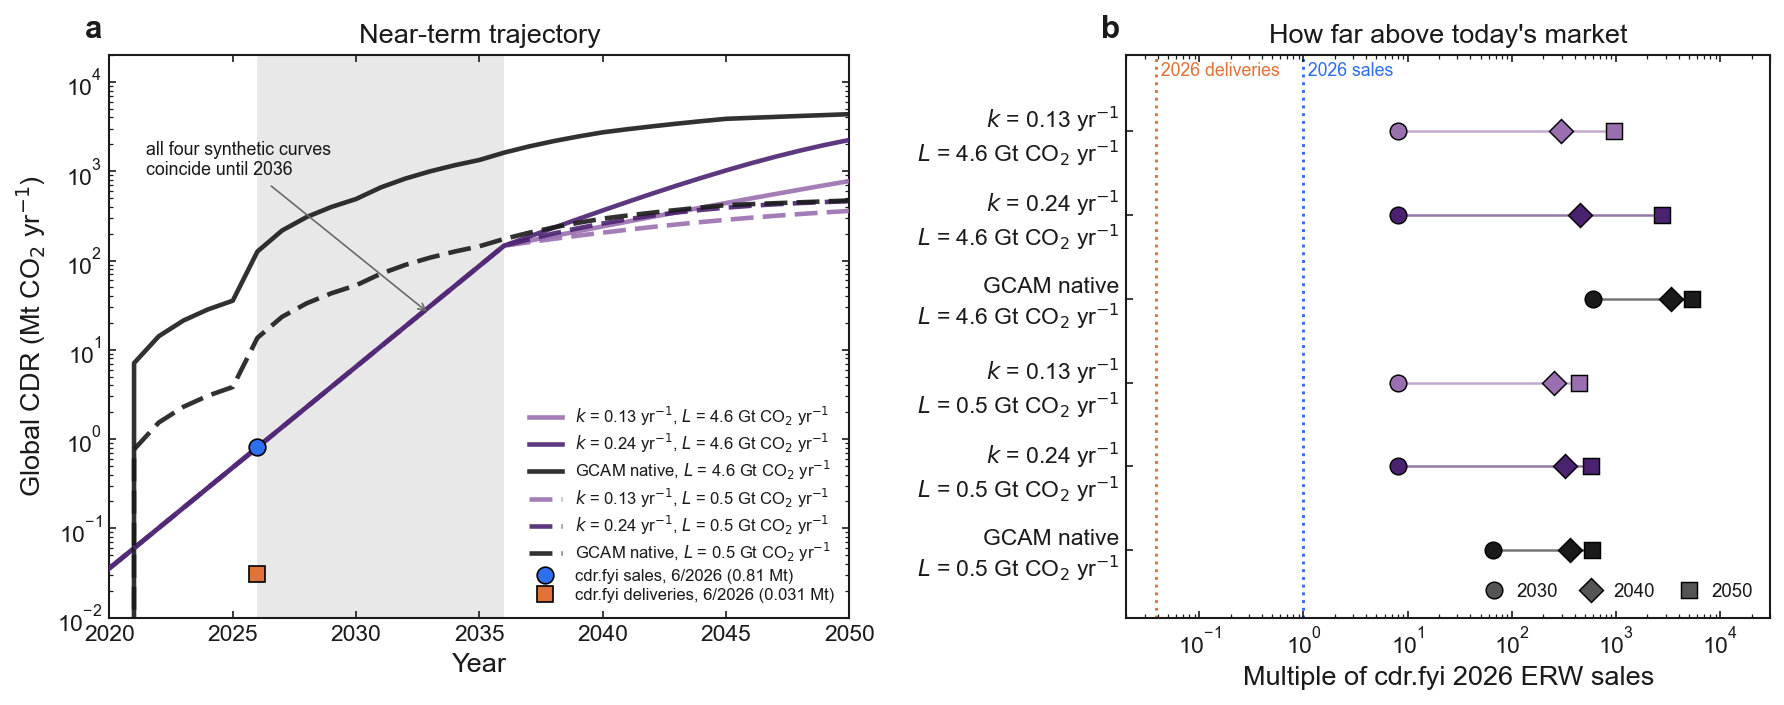

In [9]:
# ———————————————————————————————————
SAVE_ON  = False
# ———————————————————————————————————
NT_LO, NT_HI = 2020, 2050
REPORT_YEARS = [2030, 2040, 2050]
m = (years >= NT_LO) & (years <= NT_HI)

fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.8), dpi=150,
                         gridspec_kw=dict(width_ratios=[1.15, 1.0]))

# --- (a) near-term trajectory ---
ax = axes[0]
ax.axvspan(YR_BASE_CDRFYI, YR_RAMP_END, color=RAMP_SHADE, alpha=0.6, lw=0, zorder=0)
for name, L, color, ls, label in CURVE_ORDER:
    ax.plot(years[m], curves[name][m], color=color, ls=ls, lw=LW, alpha=0.9, zorder=3, label=label)
ax.plot([YR_BASE_CDRFYI], [C0_SALES_2026], "o", ms=8, color=SALES_COLOR, mec="k", mew=0.8,
        zorder=6, label="cdr.fyi sales, 6/2026 (0.81 Mt)")
ax.plot([YR_BASE_CDRFYI], [C0_DELIV_2026], "s", ms=8, color=DELIV_COLOR, mec="k", mew=0.8,
        zorder=6, label="cdr.fyi deliveries, 6/2026 (0.031 Mt)")
ax.set_yscale("log")
ax.set_ylim(1e-2, 2e4)
ax.set_xlim(NT_LO, NT_HI)
ax.set_xlabel("Year", fontsize=FS_LAB)
ax.set_ylabel("Global CDR (Mt CO$_2$ yr$^{-1}$)", fontsize=FS_LAB)
ax.set_title("Near-term trajectory", fontsize=FS_TITLE)
ax.tick_params(which="both", direction="in", top=True, right=True, labelsize=FS_TICK)
ax.legend(fontsize=8.0, frameon=False, loc="lower right", handlelength=2.0, labelspacing=0.25)
ax.annotate("all four synthetic curves\ncoincide until 2036", xy=(2033, 25),
            xytext=(2021.5, 900), fontsize=8.5, ha="left",
            arrowprops=dict(arrowstyle="->", lw=0.8, color="#6a6a6a"))

# --- (b) multiple of cdr.fyi 2026 sales ---
ax = axes[1]
MARKERS = ["o", "D", "s"]
ypos = np.arange(len(CURVE_ORDER))[::-1]
for y, (name, L, color, ls, label) in zip(ypos, CURVE_ORDER):
    vals = [curves[name][years == yr][0] / C0_SALES_2026 for yr in REPORT_YEARS]
    ax.plot(vals, [y] * len(vals), color=color, lw=1.2, alpha=0.6, zorder=2)
    for v, mk in zip(vals, MARKERS):
        ax.plot(v, y, marker=mk, ms=8, color=color, mec="k", mew=0.7, ls="none", zorder=3)
ax.axvline(1.0, color=SALES_COLOR, ls=":", lw=1.4, zorder=1)
ax.text(1.0, len(CURVE_ORDER) - 0.35, " 2026 sales", color=SALES_COLOR, fontsize=8.5, ha="left")
ax.axvline(C0_DELIV_2026 / C0_SALES_2026, color=DELIV_COLOR, ls=":", lw=1.4, zorder=1)
ax.text(C0_DELIV_2026 / C0_SALES_2026, len(CURVE_ORDER) - 0.35, " 2026 deliveries",
        color=DELIV_COLOR, fontsize=8.5, ha="left")
ax.set_xscale("log")
ax.set_xlim(2e-2, 3e4)
ax.set_ylim(-0.8, len(CURVE_ORDER) - 0.1)
ax.set_yticks(ypos)
ax.set_yticklabels([lab.replace(", $L$", "\n$L$") for *_, lab in CURVE_ORDER], fontsize=8.0)
ax.set_xlabel("Multiple of cdr.fyi 2026 ERW sales", fontsize=FS_LAB)
ax.set_title("How far above today's market", fontsize=FS_TITLE)
ax.tick_params(which="both", direction="in", top=True, labelsize=FS_TICK)
ax.legend(handles=[plt.Line2D([0], [0], marker=mk, ls="none", ms=8, color="#555555", mec="k",
                              mew=0.7, label=str(yr)) for mk, yr in zip(MARKERS, REPORT_YEARS)],
          fontsize=FS_LEG, frameon=False, loc="lower right", ncol=3, columnspacing=0.8,
          handletextpad=0.2)

for letter, ax in zip("ab", axes):
    ax.text(-0.01, 1.02, letter, transform=ax.transAxes, ha="right", va="bottom",
            fontsize=FS_LETTER, fontweight="bold")

fig.tight_layout(w_pad=2.0)
if SAVE_ON:
    fig.savefig(os.path.join(savehere, "panels", "adoption-curves-nearterm-cdrfyi.png"),
                dpi=300, bbox_inches="tight", transparent=False)
plt.show()
plt.close();

## Figure — one parameter at a time

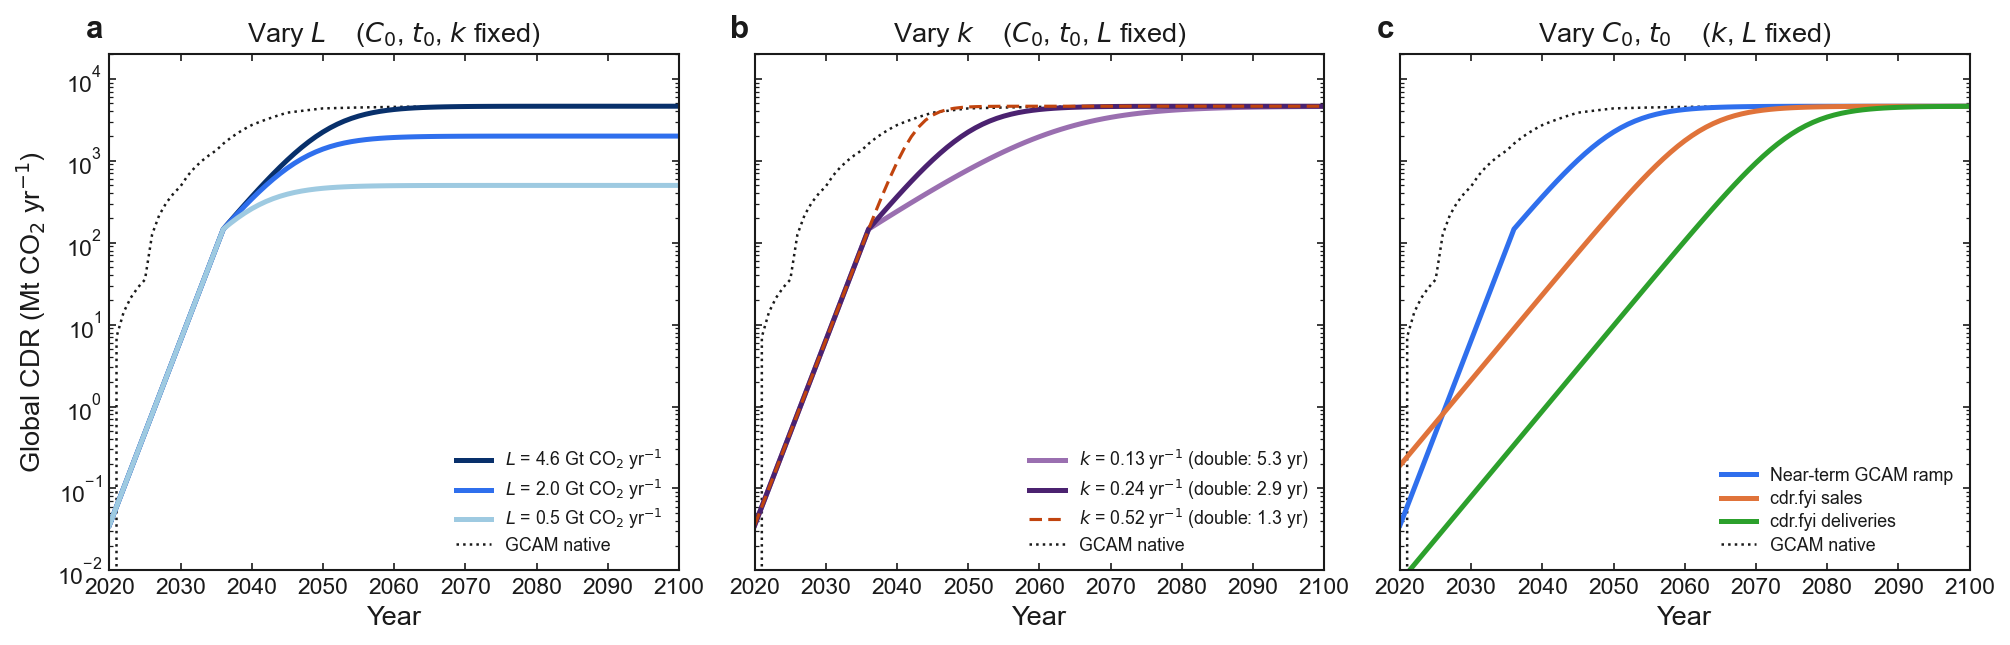

In [16]:
# ———————————————————————————————————
SAVE_ON  = True
# ———————————————————————————————————
REF  = dict(C0=float(manifest.loc[schedule_name("k_gcam", "L_gcam"), "C0"]), t0=YR_RAMP_END,
            k=K_VAL["k_gcam"], L=L_VAL["L_gcam"])
RAMP = dict(C_ref=C0_SALES_2026, t_ref=YR_BASE_CDRFYI, k=K_GCAM_10YR)

# tag: "" = in the main figure, " *" = run but not shown there, " †" = illustrative, never run
L_SWEEP  = [(L_VAL["L_gcam"], ""), (2000.0, ""), (L_VAL["L0.5Gt"], "")]
K_SWEEP  = [(K_NEMET_MEDIAN, K_COLOR["k_nemetMedian"], ""), (K_VAL["k_gcam"], K_COLOR["k_gcam"], ""),
            (K_GCAM_10YR, RAMP_COLOR, " †")]
C0_SWEEP = [("Near-term GCAM ramp", MAIN_CASE, REF["C0"], YR_RAMP_END, RAMP, ""),
            ("cdr.fyi sales", "cdrfyi-sales", C0_SALES_2026, YR_BASE_CDRFYI, None, ""),
            ("cdr.fyi deliveries", "cdrfyi-deliveries", C0_DELIV_2026, YR_BASE_CDRFYI, None, "")]
L_BLUES  = ["#08306b", "#2f6fed", "#9ecae1"]
style = lambda tag: dict(lw=2.4 if not tag else 1.5, ls="-" if not tag else (0, (4, 2)))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4), dpi=150, sharey=True)

ax = axes[0]
for color, (L_val, tag) in zip(L_BLUES, L_SWEEP):
    ax.plot(years, build_curve(years, REF["C0"], L_val, REF["k"], REF["t0"], RAMP), color=color,
            label=f"$L$ = {L_val/1e3:.1f} Gt CO$_2$ yr$^{{-1}}${tag}", **style(tag))
ax.set_title(r"Vary $L$    ($C_0$, $t_0$, $k$ fixed)", fontsize=FS_TITLE)

ax = axes[1]
for k_val, color, tag in K_SWEEP:
    ax.plot(years, build_curve(years, REF["C0"], REF["L"], k_val, REF["t0"], RAMP), color=color,
            label=f"$k$ = {k_val:.2f} yr$^{{-1}}$ (double: {np.log(2)/k_val:.1f} yr)",
            **style(tag))
ax.set_title(r"Vary $k$    ($C_0$, $t_0$, $L$ fixed)", fontsize=FS_TITLE)

ax = axes[2]
for label, case, C0_val, t0_val, ramp_val, tag in C0_SWEEP:
    ax.plot(years, build_curve(years, C0_val, REF["L"], REF["k"], t0_val, ramp_val),
            color=CASE_COLOR[case], label=f"{label}{tag}", **style(tag))
ax.set_title(r"Vary $C_0$, $t_0$    ($k$, $L$ fixed)", fontsize=FS_TITLE)

for letter, ax in zip("abc", axes):
    ax.plot(years, donor, color=GCAM_COLOR, ls=":", lw=1.2, zorder=1, label="GCAM native")
    ax.set_yscale("log")
    ax.set_ylim(1e-2, 2e4)
    ax.set_xlim(years.min(), years.max())
    ax.set_xlabel("Year", fontsize=FS_LAB)
    ax.tick_params(which="both", direction="in", top=True, right=True, labelsize=FS_TICK)
    ax.legend(fontsize=8.5, frameon=False, loc="lower right", handlelength=2.0, labelspacing=0.3)
    ax.text(-0.01, 1.02, letter, transform=ax.transAxes, ha="right", va="bottom",
            fontsize=FS_LETTER, fontweight="bold")
axes[0].set_ylabel("Global CDR (Mt CO$_2$ yr$^{-1}$)", fontsize=FS_LAB)

fig.tight_layout(w_pad=1.2)
# fig.text(0.005, -0.03, "*  generated and run, but not shown in the main figure\n"
#          "†  illustrative only -- 0.52 yr$^{-1}$ is the near-term ramp rate, never used as a long-run $k$",
#          fontsize=8.5, va="top", color="#6a6a6a")
if SAVE_ON:
    fig.savefig(os.path.join(savehere, "panels", "adoption-curves-anatomy.png"),
                dpi=300, bbox_inches="tight", transparent=False)
plt.show()
plt.close();

## Figure — gcam decomposition

k_ramp, refit on the donor over 2021-2029 (pinned at 7.089 Mt CO2/yr in 2021): k = 0.516 yr^-1, doubling 1.3 yr


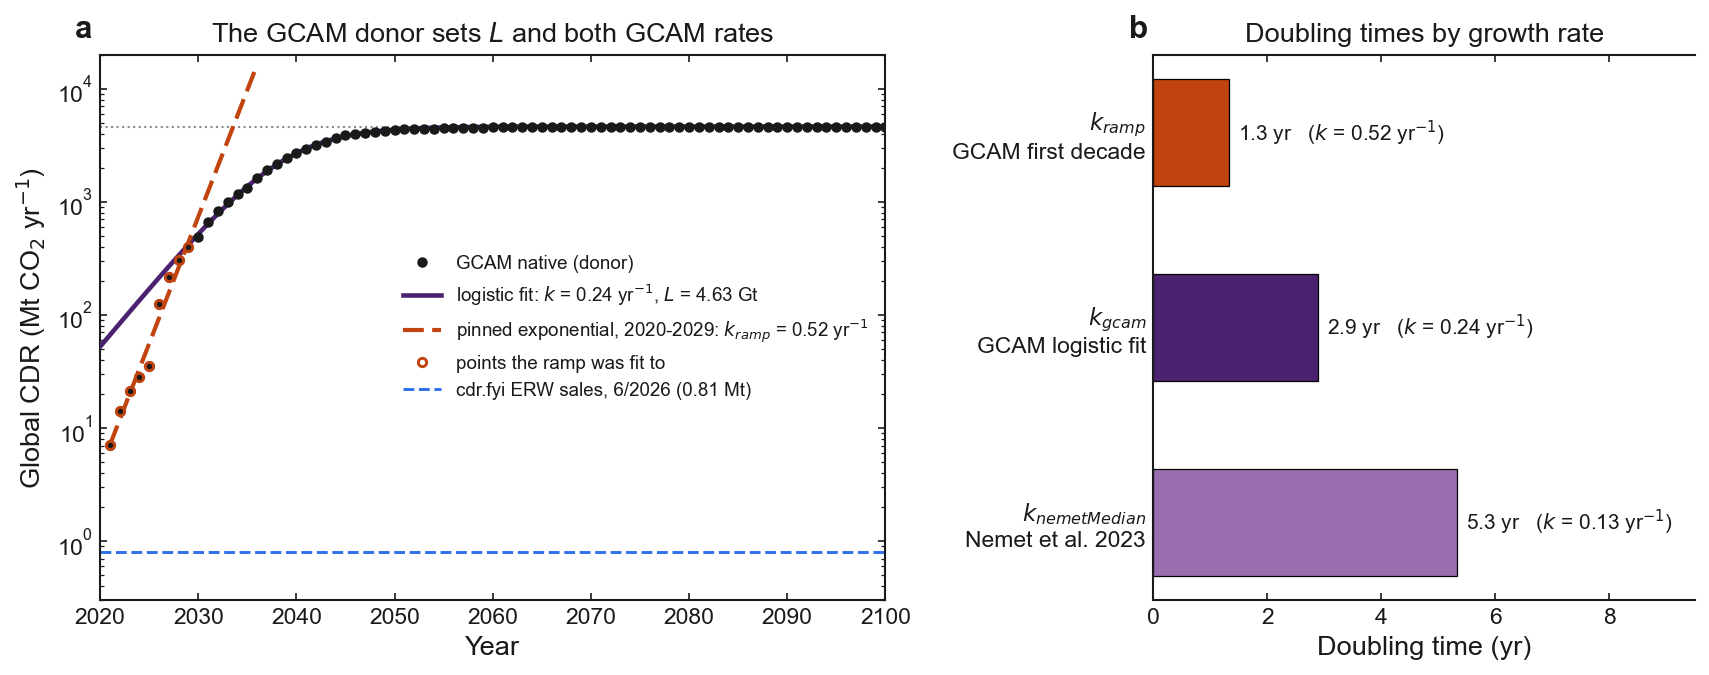

In [13]:
RAMP_FIT_WINDOW = (2020, 2029)   # as in tests/scratch-nemet-scalecurves.ipynb
SHOW_CDRFYI_SALES = True         # horizontal cdr.fyi 2026 sales line in panel a


def exponential(t, C0, k, t0):
    """C(t) = C0*e^{k(t-t0)} -- the C << L limit of the logistic."""
    return C0 * np.exp(k * (t - t0))


ramp_mask = (years >= RAMP_FIT_WINDOW[0]) & (years <= RAMP_FIT_WINDOW[1]) & (donor > 0)
t_ramp, y_ramp = years[ramp_mask], donor[ramp_mask]
t0_ramp  = t_ramp.min()                      # donor is exactly 0 in 2020, so this is 2021
C0_ramp  = y_ramp[np.argmin(t_ramp)]         # pin to that first point; k is the only free parameter
k_early  = float(curve_fit(lambda t, k: exponential(t, C0_ramp, k, t0_ramp), t_ramp, y_ramp,
                           p0=[0.2], maxfev=20000)[0][0])
print(f"k_ramp, refit on the donor over {t_ramp.min():.0f}-{t_ramp.max():.0f} "
      f"(pinned at {C0_ramp:.3f} Mt CO2/yr in {t0_ramp:.0f}): k = {k_early:.3f} yr^-1, "
      f"doubling {np.log(2)/k_early:.1f} yr")
assert round(k_early, 2) == K_GCAM_10YR, "refit no longer reproduces the adopted K_GCAM_10YR"

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), dpi=150,
                         gridspec_kw=dict(width_ratios=[1.45, 1.0]))

ax = axes[0]
ax.plot(years[years >= 2021], donor[years >= 2021], "o", ms=4, color=GCAM_COLOR, zorder=4,
        label="GCAM native (donor)")
ax.plot(years, logistic4(years, C0_fit, L_fit, k_fit, T0_REF), color=K_COLOR["k_gcam"], lw=2.2,
        zorder=3, label=f"logistic fit: $k$ = {k_fit:.2f} yr$^{{-1}}$, $L$ = {L_fit/1e3:.2f} Gt")
ramp_yrs = np.linspace(t0_ramp, YR_RAMP_END, 50)
ax.plot(ramp_yrs, exponential(ramp_yrs, C0_ramp, k_early, t0_ramp), color=RAMP_COLOR,
        lw=2.0, ls=(0, (5, 2)), zorder=3,
        label=f"pinned exponential, {RAMP_FIT_WINDOW[0]}-{RAMP_FIT_WINDOW[1]}: "
              f"$k_{{ramp}}$ = {k_early:.2f} yr$^{{-1}}$")
ax.plot(t_ramp, y_ramp, "o", ms=4, mfc="none", mec=RAMP_COLOR, mew=1.4, zorder=5,
        label="points the ramp was fit to")
ax.axhline(L_fit, color="#8a8a8a", ls=":", lw=1.0)
if SHOW_CDRFYI_SALES:
    ax.axhline(C0_SALES_2026, color=SALES_COLOR, ls="--", lw=1.4, zorder=2,
               label=f"cdr.fyi ERW sales, 6/2026 ({C0_SALES_2026:.2f} Mt)")
ax.set_yscale("log")
ax.set_ylim(0.3 if SHOW_CDRFYI_SALES else 1, 2e4)
ax.set_xlim(years.min(), years.max())
ax.set_xlabel("Year", fontsize=FS_LAB)
ax.set_ylabel("Global CDR (Mt CO$_2$ yr$^{-1}$)", fontsize=FS_LAB)
ax.set_title("The GCAM donor sets $L$ and both GCAM rates", fontsize=FS_TITLE)
ax.tick_params(which="both", direction="in", top=True, right=True, labelsize=FS_TICK)
ax.legend(fontsize=FS_LEG, frameon=False, loc="center right")

ax = axes[1]
rates = [("$k_{ramp}$\nGCAM first decade", K_GCAM_10YR, RAMP_COLOR),
         ("$k_{gcam}$\nGCAM logistic fit", K_VAL["k_gcam"], K_COLOR["k_gcam"]),
         ("$k_{nemetMedian}$\nNemet et al. 2023", K_VAL["k_nemetMedian"], K_COLOR["k_nemetMedian"])]
ypos = np.arange(len(rates))[::-1]
for y, (label, k_val, color) in zip(ypos, rates):
    t2 = np.log(2) / k_val
    ax.barh(y, t2, color=color, height=0.55, edgecolor="k", lw=0.6)
    ax.text(t2 + 0.15, y, f"{t2:.1f} yr   ($k$ = {k_val:.2f} yr$^{{-1}}$)", va="center", fontsize=10)
ax.set_yticks(ypos)
ax.set_yticklabels([r[0] for r in rates], fontsize=10)
ax.set_xlim(0, 9.5)
ax.set_xlabel("Doubling time (yr)", fontsize=FS_LAB)
ax.set_title("Doubling times by growth rate", fontsize=FS_TITLE)
ax.tick_params(which="both", direction="in", top=True, labelsize=FS_TICK)
ax.tick_params(axis="y", length=0)
ax.spines[["right"]].set_visible(False)

for letter, ax in zip("ab", axes):
    ax.text(-0.01, 1.02, letter, transform=ax.transAxes, ha="right", va="bottom",
            fontsize=FS_LETTER, fontweight="bold")

fig.tight_layout(w_pad=2.0)
if SAVE_ON:
    fig.savefig(os.path.join(savehere, "panels", "adoption-curves-rates.png"),
                dpi=300, bbox_inches="tight", transparent=False)
plt.show()
plt.close();

In [12]:
# ---